# Лабораторная работа № 15. Многослойный персептрон на PyTorch
**Дисциплина:** Методы искусственного интеллекта  
**Студент:** Мальцев Николай Артемович  
**Группа:** ИНС-м-о-25-2

**Цель:** реализация нейронной сети типа многослойный персептрон.

**Задачи:** реализовать MLP средствами PyTorch; освоить обучение; исследовать влияние архитектуры, оптимизатора и шага; проверить сеть на данных мониторинга.

**Данные:** трёхклассовая спираль «игрушка дьявола» из методички; прежний RCAEval RE2-OB для индивидуального пункта 2.

Работа выполнена по методичке *Practicum_AI_Methods.pdf*, с. 132–140. В цели исправлены только опечатки.

## 1. Локальный запуск и краткая теория
Используем окружение `rcaeval-ai`, VS Code и Jupyter. Выбираем ядро этого окружения и выполняем **Run All**. Для работ № 14–15 добавлен PyTorch с расчётами на CPU; видеокарта не нужна. Из корня проекта окружение обновляется командой:
```bash
conda env update --prefix .conda/rcaeval-ai -f environment.yml
```
Ноутбук выполняется самостоятельно. Сохранённые данные читаются локально; другие ноутбуки запускать не нужно. Результаты и рисунки сохраняются в `reports/labXX/`, где XX — номер работы.

Подключаем библиотеки для таблиц, файлов и рисунков.

In [1]:
from pathlib import Path
from urllib.request import urlopen
from importlib.metadata import version
import json
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

Подключаем методы обучения и проверки.

In [2]:
import torch
from torch import nn
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.metrics import accuracy_score, confusion_matrix, log_loss

Задаём пути и настройки.

In [3]:
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'environment.yml').is_file() and (p / 'notebooks').is_dir())
REPORT = ROOT / 'reports/lab15'
FIGURES = REPORT / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
SEED = 17
sns.set_theme(style='whitegrid')

torch.manual_seed(SEED)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)

Печатаем и сохраняем версии библиотек.

In [4]:
versions = {'Python': platform.python_version()}
versions.update({name: version(name) for name in ['numpy', 'pandas', 'matplotlib', 'scikit-learn', 'torch']})
display(pd.Series(versions, name='Версия'))
(REPORT / 'versions.json').write_text(json.dumps(versions, indent=2), encoding='utf-8')

Python          3.11.17
numpy             2.2.6
pandas            2.3.3
matplotlib       3.10.9
scikit-learn      1.7.2
torch            2.14.1
Name: Версия, dtype: object

140

Определяем сохранение и показ рисунка.

In [5]:
def save_show(fig, filename):
    fig.savefig(FIGURES / filename, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

MLP состоит из нескольких полносвязных слоёв. `Linear` вычисляет взвешенную сумму и смещение, ReLU или Tanh добавляет нелинейность. Без неё несколько линейных слоёв были бы одним линейным преобразованием.

При прямом проходе получаем оценки классов. Функция потерь сравнивает их с правильными ответами. `backward()` вычисляет градиенты, а `optimizer.step()` меняет веса. В этой работе используем PyTorch, а не готовый MLPClassifier. Все расчёты выполняются на CPU.

Определяем создание спирального набора по формуле методички.

In [6]:
def make_spiral(seed=SEED):
    rng = np.random.RandomState(seed)
    N, D, K = 100, 2, 3
    X = np.zeros((N * K, D), dtype=np.float32)
    y = np.zeros(N * K, dtype=np.int64)
    for j in range(K):
        rows = range(N * j, N * (j + 1))
        r = np.linspace(0, 1, N)
        angle = np.linspace(j * 4, (j + 1) * 4, N) + rng.randn(N) * 0.2
        X[rows] = np.c_[r * np.sin(angle), r * np.cos(angle)]
        y[rows] = j
    return X, y

Определяем рисование областей решения.

In [7]:
def draw_boundary(ax, predict, X, y, title, names=None):
    low, high = X.min(axis=0) - 0.25, X.max(axis=0) + 0.25
    xx, yy = np.meshgrid(np.linspace(low[0], high[0], 180), np.linspace(low[1], high[1], 180))
    grid = np.c_[xx.ravel(), yy.ravel()]
    classes = np.unique(y)
    levels = np.arange(len(classes) + 1) - 0.5
    ax.contourf(xx, yy, predict(grid).reshape(xx.shape), levels=levels, cmap='coolwarm', alpha=0.22)
    for label in classes:
        rows = y == label
        name = str(label) if names is None else names[int(label)]
        ax.scatter(X[rows, 0], X[rows, 1], c=np.full(rows.sum(), label), cmap='coolwarm',
                   vmin=0, vmax=max(1, len(classes)-1), s=15, edgecolors='k', linewidths=0.2, label=name)
    ax.set(title=title, xlabel='Признак 1', ylabel='Признак 2', xlim=(low[0],high[0]), ylim=(low[1],high[1]))
    ax.legend(title='Настоящий класс', fontsize=8)

Определяем обучение по всему обучающему набору за эпоху.

In [8]:
def train_network(model, X, y, optimizer, loss_fn, epochs):
    x_tensor = torch.as_tensor(X, dtype=torch.float32)
    y_tensor = torch.as_tensor(y, dtype=torch.long)
    history = []
    model.train()
    for epoch in range(epochs):
        optimizer.zero_grad()
        loss = loss_fn(model(x_tensor), y_tensor)
        loss.backward()
        optimizer.step()
        history.append(loss.item())
    return history

Определяем получение классов без вычисления градиентов.

In [9]:
def predict_network(model, X):
    model.eval()
    with torch.no_grad():
        output = model(torch.as_tensor(X, dtype=torch.float32))
        if output.shape[1] == 1:
            return (output[:, 0] >= 0).numpy().astype(int)
        return output.argmax(dim=1).numpy()

Определяем MLP с заданными скрытыми слоями и активацией.

In [10]:
def make_network(input_size, hidden, output_size, activation='relu'):
    layers = []
    width = input_size
    for neurons in hidden:
        layers.append(nn.Linear(width, neurons))
        layers.append(nn.ReLU() if activation == 'relu' else nn.Tanh())
        width = neurons
    layers.append(nn.Linear(width, output_size))
    return nn.Sequential(*layers)

Определяем запуск обучения с фиксированными начальными весами.

In [11]:
def fit_mlp(X, y, config, output_size):
    torch.manual_seed(SEED)
    model = make_network(X.shape[1], config['hidden'], output_size, config['activation'])
    if config['optimizer'] == 'SGD':
        optimizer = torch.optim.SGD(model.parameters(), lr=config['lr'], momentum=config.get('momentum', 0))
    else:
        optimizer = torch.optim.Adam(model.parameters(), lr=config['lr'])
    loss_fn = nn.CrossEntropyLoss(reduction=config.get('reduction', 'mean'))
    history = train_network(model, X, y, optimizer, loss_fn, config['epochs'])
    return model, history

def network_probabilities(model, X):
    model.eval()
    with torch.no_grad():
        return model(torch.as_tensor(X, dtype=torch.float32)).softmax(dim=1).numpy()

## 2. Учебная задача: MLP для «игрушки дьявола»
### 2.1. Три спиральных класса
Создаём тот же набор, что в работе № 14: 300 точек, по 100 в классе, две координаты, шум угла 0,2, seed 17. Это обязательный учебный набор из методички, а реальные данные мониторинга используются далее.

В начале каждой спирали радиус равен нулю: несколько точек разных классов совпадают. По одним и тем же координатам нельзя всегда различить разные метки. Не удаляем такие точки ради высокой accuracy.

Создаём исходные точки и ответы.

In [12]:
Xs, ys = make_spiral()
print('Размер:', Xs.shape, '| Классы:', np.bincount(ys))

Размер: (300, 2) | Классы: [100 100 100]


Показываем исходную спираль.

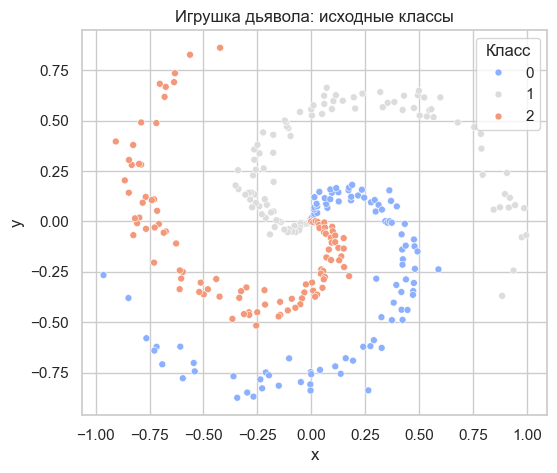

In [13]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.scatterplot(x=Xs[:, 0], y=Xs[:, 1], hue=ys.astype(str), palette='coolwarm', s=25, ax=ax)
ax.set(title='Игрушка дьявола: исходные классы', xlabel='x', ylabel='y')
ax.legend(title='Класс')
save_show(fig, '01_spiral_data.png')

Цвет показывает один из трёх классов. Изгибы не удаётся описать прямыми границами из предыдущей работы. Скрытый слой с нелинейной активацией позволяет построить более сложное разделение.

Отделяем обучение, подбор и итоговую проверку.

In [14]:
s_develop, s_test = train_test_split(np.arange(len(ys)), test_size=0.2, stratify=ys, random_state=SEED)
s_train, s_valid = train_test_split(s_develop, test_size=0.25, stratify=ys[s_develop], random_state=SEED)
s_scaler = StandardScaler().fit(Xs[s_train])
s_train_X, s_valid_X, s_test_X = [s_scaler.transform(Xs[rows]).astype(np.float32)
                                 for rows in [s_train, s_valid, s_test]]
print('Обучение / подбор / итоговая проверка:', len(s_train), len(s_valid), len(s_test))

Обучение / подбор / итоговая проверка: 180 60 60


### 2.2. Повторяем исходную сеть из примера
На с. 137 сеть имеет один скрытый слой из 100 ReLU-нейронов и три выхода. Обучается SGD с шагом 0,0001, 500 эпох; CrossEntropy суммируется по строкам. Повторяем эти настройки на обучающей части, добавив подготовку масштаба и отдельные проверочные точки.

В отличие от пояснения на с. 138, CrossEntropyLoss **не требует и не выполняет явное OneHot-кодирование** при метках `LongTensor` 0, 1, 2. Она использует номер правильного класса при вычислении потери. На вход функции передаём исходные оценки, без sigmoid и softmax.

Задаём и обучаем исходный MLP из методички.

In [15]:
baseline_config = {'name': 'Пример: 100 ReLU, SGD', 'hidden': (100,), 'activation': 'relu',
                   'optimizer': 'SGD', 'lr': 0.0001, 'epochs': 500, 'reduction': 'sum'}
baseline_model, baseline_history = fit_mlp(s_train_X, ys[s_train], baseline_config, output_size=3)
print(baseline_model)
print('Обучаемых параметров:', sum(p.numel() for p in baseline_model.parameters()))
print('Accuracy на части подбора:', accuracy_score(ys[s_valid], predict_network(baseline_model, s_valid_X)))

Sequential(
  (0): Linear(in_features=2, out_features=100, bias=True)
  (1): ReLU()
  (2): Linear(in_features=100, out_features=3, bias=True)
)
Обучаемых параметров: 603
Accuracy на части подбора: 0.7


Показываем исходную границу и ход обучения.

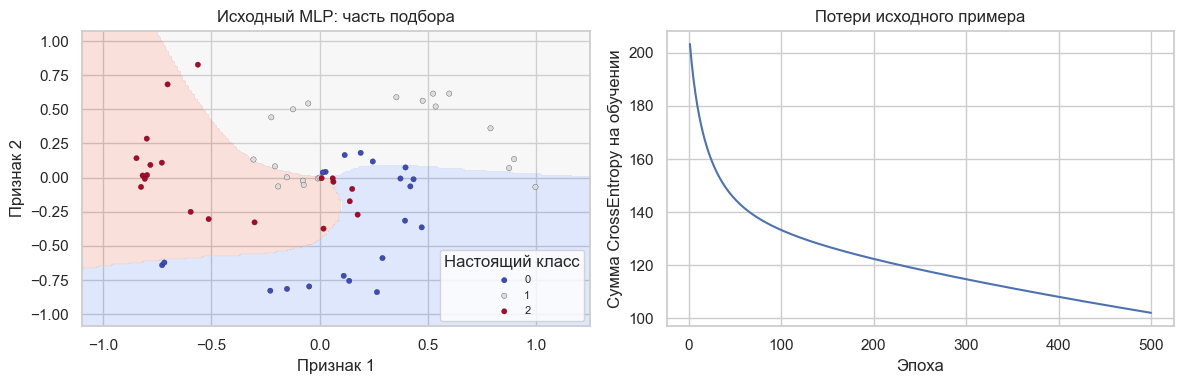

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
predict = lambda raw: predict_network(baseline_model, s_scaler.transform(raw))
draw_boundary(axes[0], predict, Xs[s_valid], ys[s_valid], 'Исходный MLP: часть подбора')
axes[1].plot(np.arange(1, len(baseline_history) + 1), baseline_history)
axes[1].set(title='Потери исходного примера', xlabel='Эпоха', ylabel='Сумма CrossEntropy на обучении')
fig.tight_layout()
save_show(fig, '02_baseline_boundary_loss.png')

Слева сеть даёт ответ для каждой точки плоскости; точки показывают настоящие классы части подбора. Ошибки видны по несовпадению цветов. Справа потери обучения. Если граница остаётся грубой, причина может быть в коротком обучении и маленьком шаге, а не только в числе нейронов.

## 3. Индивидуальное задание
### 3.1. Улучшаем MLP — пункт 1
Сравниваем исходную сеть и четыре варианта обучения. Меняем глубину, активацию, оптимизатор, шаг и число эпох. Это сравнение готовых сочетаний, а не отдельная оценка влияния каждого параметра.

Выбираем вариант только по части подбора: сначала максимальная accuracy, затем меньшая LogLoss. Все варианты используют одни и те же точки и масштаб. Итоговая тестовая часть не участвует в выборе.

Задаём варианты улучшенного MLP.

In [17]:
spiral_configs = [baseline_config,
    {'name': '100 ReLU, Adam', 'hidden': (100,), 'activation': 'relu', 'optimizer': 'Adam', 'lr': 0.01, 'epochs': 1500},
    {'name': '64–64 Tanh, Adam', 'hidden': (64, 64), 'activation': 'tanh', 'optimizer': 'Adam', 'lr': 0.01, 'epochs': 1500},
    {'name': '64–64 ReLU, Adam', 'hidden': (64, 64), 'activation': 'relu', 'optimizer': 'Adam', 'lr': 0.01, 'epochs': 1500},
    {'name': '64–64 Tanh, SGD', 'hidden': (64, 64), 'activation': 'tanh', 'optimizer': 'SGD', 'lr': 0.05, 'momentum': 0.9, 'epochs': 2000}
]

Обучаем варианты и сравниваем их на части подбора.

In [18]:
spiral_models = {baseline_config['name']: baseline_model}
spiral_histories = {baseline_config['name']: baseline_history}
spiral_rows = []
for config in spiral_configs:
    name = config['name']
    if name != baseline_config['name']:
        model, history = fit_mlp(s_train_X, ys[s_train], config, output_size=3)
        spiral_models[name], spiral_histories[name] = model, history
    model = spiral_models[name]
    probability = network_probabilities(model, s_valid_X)
    spiral_rows.append({'name': name, 'hidden': config['hidden'], 'activation': config['activation'],
        'optimizer': config['optimizer'], 'lr': config['lr'], 'epochs': config['epochs'],
        'parameters': sum(p.numel() for p in model.parameters()),
        'train_accuracy': accuracy_score(ys[s_train], predict_network(model, s_train_X)),
        'valid_accuracy': accuracy_score(ys[s_valid], probability.argmax(axis=1)),
        'valid_logloss': log_loss(ys[s_valid], probability)})
spiral_table = pd.DataFrame(spiral_rows)
display(spiral_table)
best_name = spiral_table.sort_values(['valid_accuracy', 'valid_logloss'], ascending=[False, True]).iloc[0]['name']
best_config = next(config for config in spiral_configs if config['name'] == best_name)
print('Выбрано до просмотра теста:', best_name)

,name,hidden,activation,optimizer,lr,epochs,parameters,train_accuracy,valid_accuracy,valid_logloss
0,"Пример: 100 ReLU, SGD","(100,)",relu,SGD,0.0001,500,603,0.727778,0.700000,0.550090
1,"100 ReLU, Adam","(100,)",relu,Adam,0.0100,1500,603,0.994444,0.983333,0.072154
2,"64–64 Tanh, Adam","(64, 64)",tanh,Adam,0.0100,1500,4547,0.994444,0.983333,0.124468
3,"64–64 ReLU, Adam","(64, 64)",relu,Adam,0.0100,1500,4547,0.994444,0.983333,0.126908
4,"64–64 Tanh, SGD","(64, 64)",tanh,SGD,0.0500,2000,4547,0.994444,0.983333,0.070618


Выбрано до просмотра теста: 64–64 Tanh, SGD


Сравниваем области решений всех вариантов на одинаковых точках.

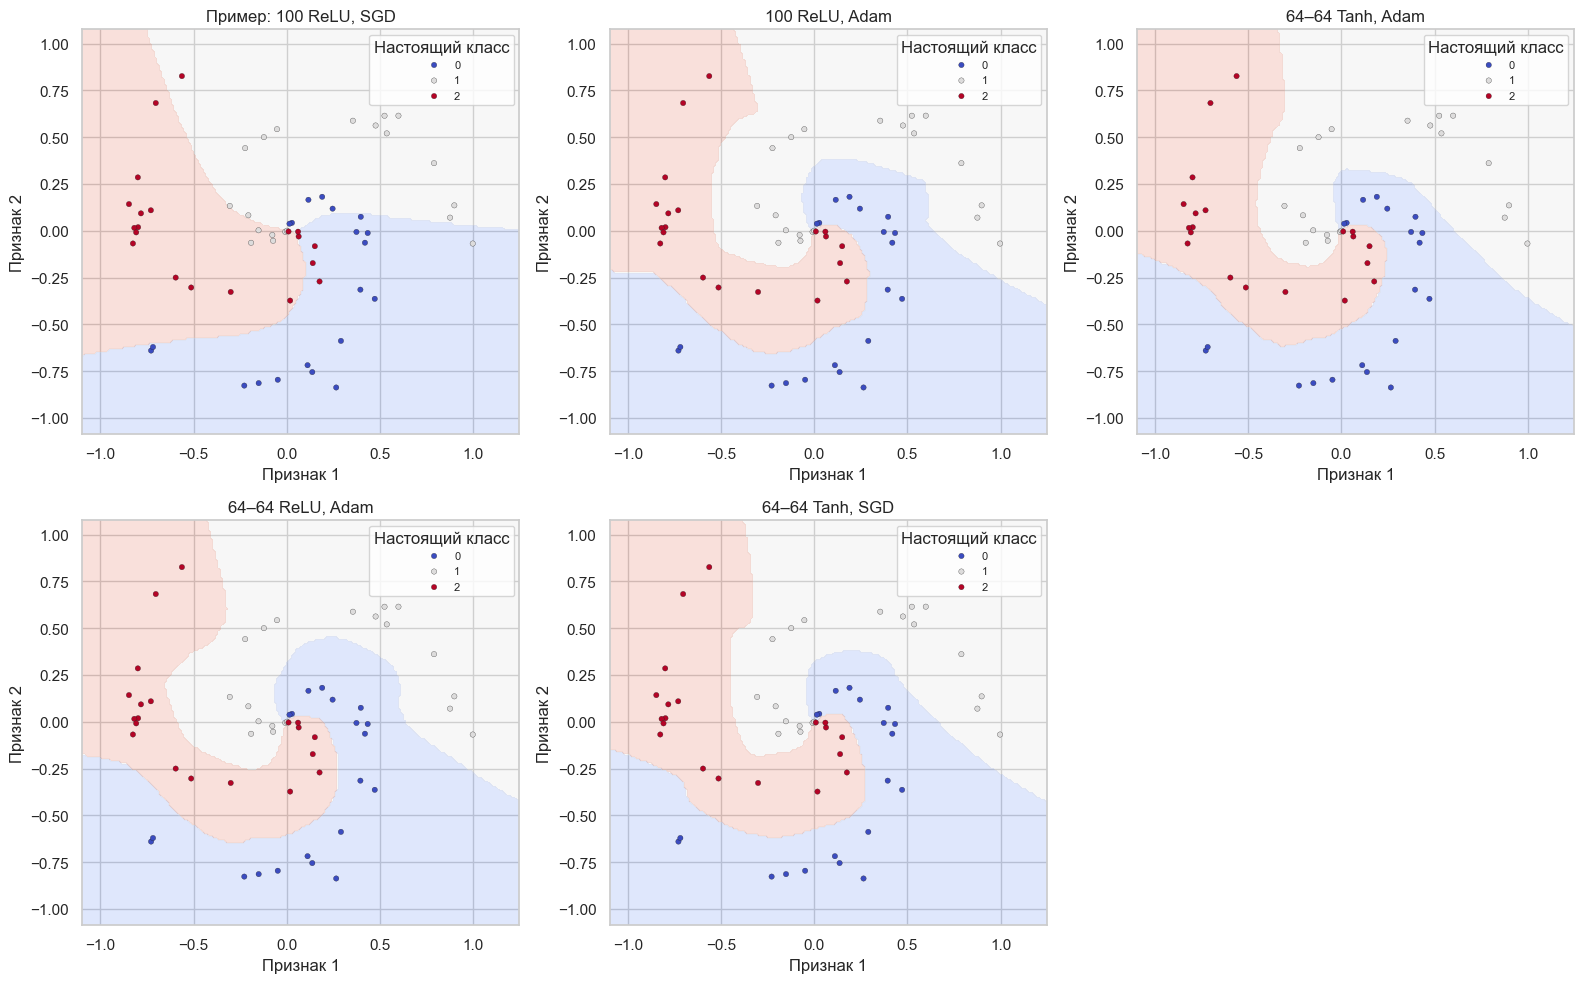

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, config in zip(axes.flat, spiral_configs):
    name = config['name']
    predict = lambda raw, name=name: predict_network(spiral_models[name], s_scaler.transform(raw))
    draw_boundary(ax, predict, Xs[s_valid], ys[s_valid], name)
axes.flat[-1].axis('off')
fig.tight_layout()
save_show(fig, '03_improved_boundaries.png')

На всех панелях те же проверочные точки. Улучшенная сеть может изгибать границу по форме спиралей. Узкие или лишние цветные участки вдали от точек не подтверждены наблюдениями. Число параметров и accuracy приведены рядом в таблице: большая сеть не автоматически лучший вариант.

Показываем обучение улучшенных вариантов с одинаковым усреднением потерь.

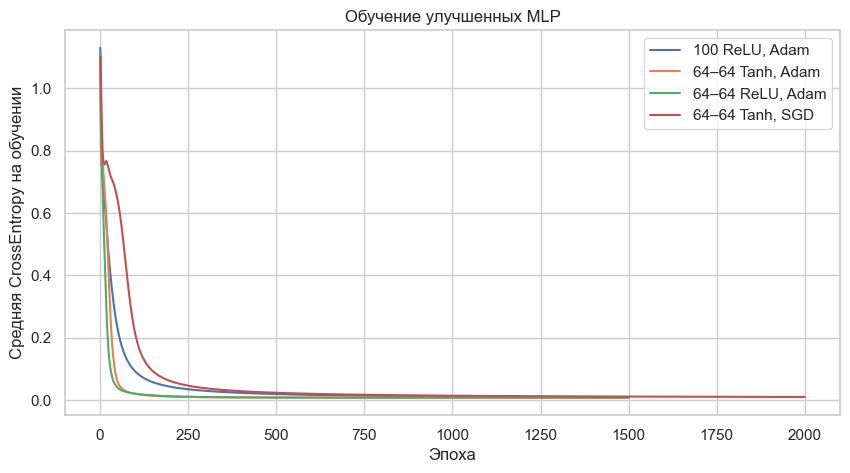

In [20]:
fig, ax = plt.subplots(figsize=(10, 5))
for config in spiral_configs[1:]:
    name = config['name']
    ax.plot(np.arange(1, len(spiral_histories[name]) + 1), spiral_histories[name], label=name)
ax.set(title='Обучение улучшенных MLP', xlabel='Эпоха', ylabel='Средняя CrossEntropy на обучении')
ax.legend()
save_show(fig, '04_improved_loss.png')

Все эти линии показывают средние потери по обучающим строкам. Более быстрое уменьшение говорит о ходе обучения, но победитель выбирается по отдельной части подбора. Сумма потерь исходного примера показана отдельно, чтобы не сравнивать разные шкалы.

Проверяем исходный и выбранный MLP на итоговых спиральных точках.

In [21]:
spiral_test_rows, spiral_predictions = [], {}
for name in dict.fromkeys([baseline_config['name'], best_name]):
    predicted = predict_network(spiral_models[name], s_test_X)
    spiral_predictions[name] = predicted
    spiral_test_rows.append({'name': name, 'test_accuracy': accuracy_score(ys[s_test], predicted)})
spiral_test_table = pd.DataFrame(spiral_test_rows)
display(spiral_test_table)

,name,test_accuracy
0,"Пример: 100 ReLU, SGD",0.683333
1,"64–64 Tanh, SGD",0.966667


Показываем ошибки исходной и выбранной сетей на итоговом тесте.

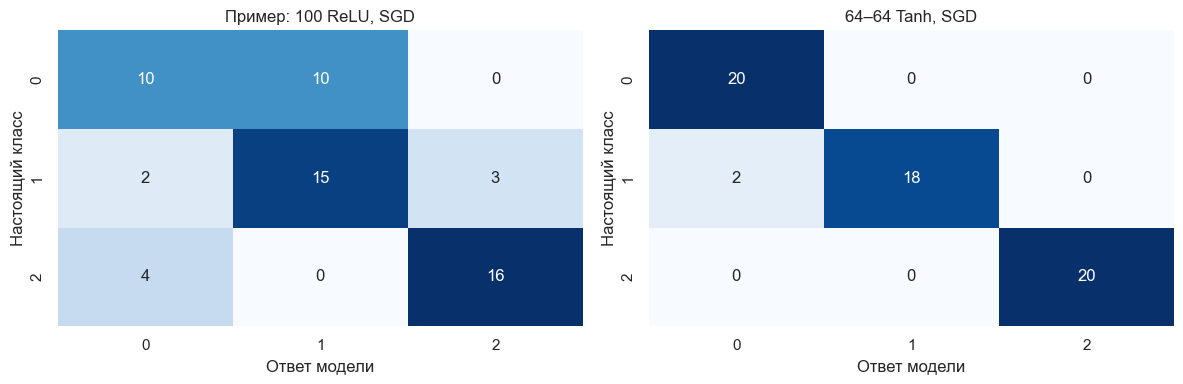

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, name in zip(axes, [baseline_config['name'], best_name]):
    sns.heatmap(confusion_matrix(ys[s_test], spiral_predictions[name], labels=[0, 1, 2]),
                annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
    ax.set(title=name, xlabel='Ответ модели', ylabel='Настоящий класс')
fig.tight_layout()
save_show(fig, '05_spiral_test_confusion.png')

Диагональ — правильные ответы, остальные клетки — перепутанные классы. Здесь новые точки, которые не участвовали в подборе настроек. На основе этих ошибок не меняем выбранную модель. Небольшой тест не позволяет точно оценить поведение на любых новых спиралях.

### 3.2. Проверяем MLP на прежнем RCAEval — пункт 2
Используем тот же сценарий CPU stress в checkoutservice. Исходная таблица содержит 1441 момент, 72 метрики и время. Берём пять настоящих показателей checkoutservice: CPU, память, socket, workload и медианную задержку.

Цель классификации — период до/начиная с внесения сбоя. Это не разметка каждого момента как доказанно аварийного. Время служит только для меток и разделения, а не для входа сети.

**Согласование датасета с преподавателем:** ____________________  
**Дата:** ____________________

Читаем прежние локальные данные без повторного скачивания.

In [23]:
selection = json.loads((ROOT / 'reports/lab01/selected_case.json').read_text(encoding='utf-8'))
case_dir = ROOT / 'data/raw/rcaeval' / selection['case']
metrics_path, inject_path = case_dir / 'metrics.parquet', case_dir / 'inject_time.txt'
df = pd.read_parquet(metrics_path)
inject_time = int(inject_path.read_text().strip())

Показываем выбранные метрики и задаём ответы.

In [24]:
features = ['checkoutservice_cpu', 'checkoutservice_mem', 'checkoutservice_socket',
            'checkoutservice_workload', 'checkoutservice_latency-50']
X_rca = df[features]
y_rca = (df.time >= inject_time).to_numpy(dtype=np.int64)
groups = ((df.time - df.time.min()) // 60).astype(int).to_numpy()
display(X_rca.head())
print('Исходная таблица:', df.shape, '| Признаки:', X_rca.shape)
display(X_rca.isna().sum().rename('Пропуски'))

,checkoutservice_cpu,checkoutservice_mem,checkoutservice_socket,checkoutservice_workload,checkoutservice_latency-50
0,0.215886,11702272.0,9.0,0.8,0.243182
1,0.380058,11706368.0,9.0,1.0,0.299999
2,0.380058,11706368.0,9.0,1.0,0.299999
3,0.380058,11706368.0,9.0,1.0,0.299999
4,0.380058,11706368.0,9.0,1.0,0.299999


Исходная таблица: (1441, 73) | Признаки: (1441, 5)


checkoutservice_cpu           0
checkoutservice_mem           0
checkoutservice_socket        0
checkoutservice_workload      0
checkoutservice_latency-50    0
Name: Пропуски, dtype: int64

Отделяем целые минуты для обучения, подбора и итоговой проверки.

In [25]:
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
r_develop, r_test = next(outer.split(X_rca, y_rca, groups))
inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_pos, valid_pos = next(inner.split(X_rca.iloc[r_develop], y_rca[r_develop], groups[r_develop]))
r_train, r_valid = r_develop[train_pos], r_develop[valid_pos]
print('Обучение / подбор / тест:', len(r_train), len(r_valid), len(r_test))

Обучение / подбор / тест: 901 240 300


Обучаем подготовку только по обучающим минутам.

In [26]:
rca_prepare = Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())])
r_train_X = rca_prepare.fit_transform(X_rca.iloc[r_train]).astype(np.float32)
r_valid_X = rca_prepare.transform(X_rca.iloc[r_valid]).astype(np.float32)
r_test_X = rca_prepare.transform(X_rca.iloc[r_test]).astype(np.float32)

Медианы и масштаб рассчитаны только по обучению. Соседние измерения похожи, поэтому целые минутные участки находятся в одной части. Проверяем новые минуты того же эксперимента; это не прогноз будущего и не проверка других типов сбоев.

Переносим выбранную архитектуру и задаём линейную модель для сравнения.

In [27]:
rca_configs = [
    {'name': 'Линейный выход без скрытого слоя', 'hidden': (), 'activation': 'relu',
     'optimizer': 'Adam', 'lr': 0.01, 'epochs': 1000},
    {**best_config, 'name': 'MLP из опыта со спиралью', 'reduction': 'mean'},
    {**best_config, 'name': 'MLP с меньшим шагом', 'lr': best_config['lr'] / 3, 'reduction': 'mean'}
]

Переносим форму выбранной сети и способ обучения, а не выученные на спирали веса. Здесь другой смысл данных: пять входов и два класса вместо двух входов и трёх классов. Веса для RCAEval обучаются заново. Линейная модель позволяет увидеть, нужен ли скрытый слой в этой конкретной задаче.

Сравниваем настройки MLP на части подбора RCAEval.

In [28]:
rca_models, rca_histories, rca_rows = {}, {}, []
for config in rca_configs:
    name = config['name']
    model, history = fit_mlp(r_train_X, y_rca[r_train], config, output_size=2)
    rca_models[name], rca_histories[name] = model, history
    probability = network_probabilities(model, r_valid_X)
    rca_rows.append({'name': name, 'parameters': sum(p.numel() for p in model.parameters()),
                     'valid_accuracy': accuracy_score(y_rca[r_valid], probability.argmax(axis=1)),
                     'valid_logloss': log_loss(y_rca[r_valid], probability)})
rca_table = pd.DataFrame(rca_rows)
display(rca_table)
mlp_names = [config['name'] for config in rca_configs[1:]]
rca_best = rca_table[rca_table.name.isin(mlp_names)].sort_values(
    ['valid_accuracy', 'valid_logloss'], ascending=[False, True]).iloc[0]['name']
print('Выбранный MLP по части подбора:', rca_best)

,name,parameters,valid_accuracy,valid_logloss
0,Линейный выход без скрытого слоя,12,1.000000,0.070873
1,MLP из опыта со спиралью,4674,0.958333,0.262324
2,MLP с меньшим шагом,4674,0.958333,0.076837


Выбранный MLP по части подбора: MLP с меньшим шагом


Проверяем выбранный MLP и линейное сравнение на отложенных минутах.

In [29]:
rca_test_rows, rca_predictions = [], {}
for name in [rca_configs[0]['name'], rca_best]:
    predicted = predict_network(rca_models[name], r_test_X)
    rca_predictions[name] = predicted
    rca_test_rows.append({'name': name, 'test_accuracy': accuracy_score(y_rca[r_test], predicted)})
rca_test_table = pd.DataFrame(rca_test_rows)
display(rca_test_table)

,name,test_accuracy
0,Линейный выход без скрытого слоя,1.0
1,MLP с меньшим шагом,1.0


Показываем ход обучения MLP и ошибки на отложенных данных.

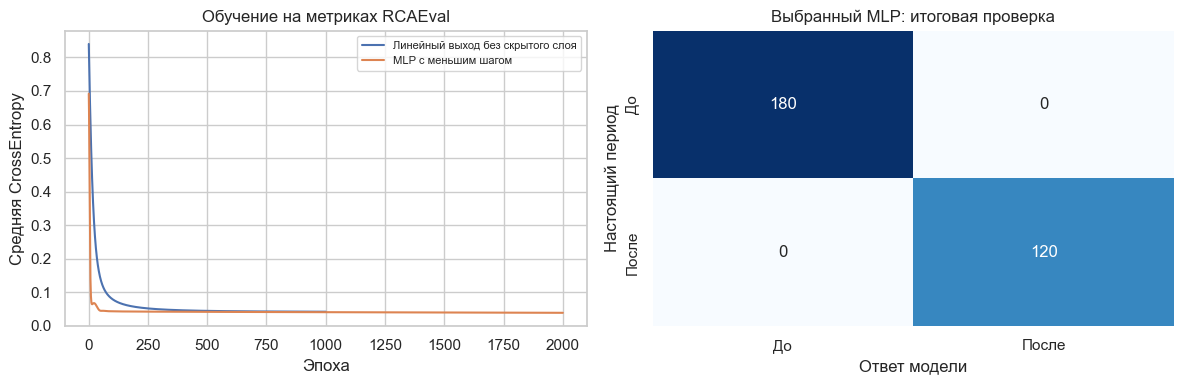

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name in [rca_configs[0]['name'], rca_best]:
    axes[0].plot(np.arange(1, len(rca_histories[name]) + 1), rca_histories[name], label=name)
axes[0].set(title='Обучение на метриках RCAEval', xlabel='Эпоха', ylabel='Средняя CrossEntropy')
axes[0].legend(fontsize=8)
sns.heatmap(confusion_matrix(y_rca[r_test], rca_predictions[rca_best], labels=[0, 1]),
            annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['До', 'После'], yticklabels=['До', 'После'], ax=axes[1])
axes[1].set(title='Выбранный MLP: итоговая проверка', xlabel='Ответ модели', ylabel='Настоящий период')
fig.tight_layout()
save_show(fig, '06_rca_loss_confusion.png')

Слева уменьшаются потери обучения линейного сравнения и MLP. Справа — правильные и ошибочные ответы выбранного MLP на новых минутах. Если обе модели уже хорошо различают периоды, дополнительные слои не обязаны дать выигрыш; на спирали и на метриках сложность задачи различается.

Показываем ответы выбранного MLP по времени.

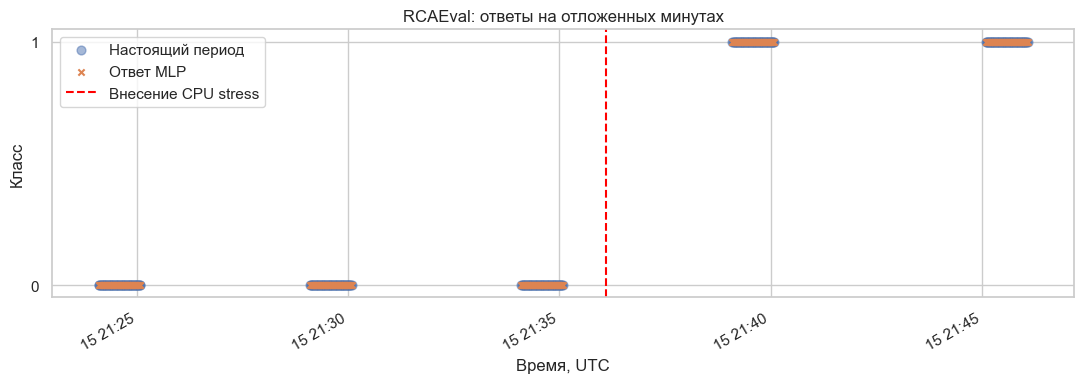

In [31]:
fig, ax = plt.subplots(figsize=(11, 4))
test_time = pd.to_datetime(df.time.iloc[r_test], unit='s', utc=True)
ax.scatter(test_time, y_rca[r_test], label='Настоящий период', s=40, alpha=0.5)
ax.scatter(test_time, rca_predictions[rca_best], label='Ответ MLP', s=20, marker='x')
ax.axvline(pd.to_datetime(inject_time, unit='s', utc=True), color='red', linestyle='--', label='Внесение CPU stress')
ax.set(title='RCAEval: ответы на отложенных минутах', xlabel='Время, UTC', ylabel='Класс', yticks=[0, 1])
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
save_show(fig, '07_rca_predictions_time.png')

На рисунке только отложенные минуты. Совпадение маркеров означает правильный ответ, вертикальный пунктир — известный момент внесения CPU stress. Промежутки без точек соответствуют другим минутам, а не пропавшим измерениям исходного набора. Сеть получает метрики текущего момента, поэтому это классификация, а не прогноз заранее.

Сохраняем таблицы, ответы, веса и простой текст результата.

In [32]:
spiral_table.to_csv(REPORT / 'spiral_validation.csv', index=False)
spiral_test_table.to_csv(REPORT / 'spiral_test.csv', index=False)
pd.DataFrame({'row': s_test, 'actual': ys[s_test], **spiral_predictions}).to_csv(REPORT / 'spiral_predictions.csv', index=False)
rca_table.to_csv(REPORT / 'rca_validation.csv', index=False)
rca_test_table.to_csv(REPORT / 'rca_test.csv', index=False)
pd.DataFrame({'row': r_test, 'actual': y_rca[r_test], **rca_predictions}).to_csv(REPORT / 'rca_predictions.csv', index=False)
np.savez_compressed(REPORT / 'split_indices.npz', spiral_train=s_train, spiral_valid=s_valid, spiral_test=s_test,
                    rca_train=r_train, rca_valid=r_valid, rca_test=r_test)
torch.save(spiral_models[best_name].state_dict(), REPORT / 'spiral_weights.pt')
torch.save(rca_models[rca_best].state_dict(), REPORT / 'rca_weights.pt')
spiral_accuracy = accuracy_score(ys[s_test], spiral_predictions[best_name])
rca_accuracy = accuracy_score(y_rca[r_test], rca_predictions[rca_best])
analysis = (f'Реализовал многослойный персептрон на PyTorch. Для спирали по части подбора выбран '
            f'вариант «{best_name}»; на {len(s_test)} итоговых точках accuracy = {spiral_accuracy:.1%}. '
            f'На прежнем RCAEval выбран «{rca_best}», на {len(r_test)} отложенных строках '
            f'accuracy = {rca_accuracy:.1%}. Скрытые слои позволяют изгибать границы, но сами по себе '
            'не гарантируют выигрыш в любой задаче. Выбор настроек выполнялся до просмотра итогового теста.')
display(Markdown(analysis))
(REPORT / 'analysis.md').write_text(analysis, encoding='utf-8')
summary = {'spiral_selected': best_name, 'spiral_test': spiral_test_table.to_dict('records'),
           'rca_selected': rca_best, 'rca_test': rca_test_table.to_dict('records'),
           'rca_split': [len(r_train), len(r_valid), len(r_test)],
           'case': selection['case'], 'features': features,
           'figures': sorted(p.name for p in FIGURES.glob('*.png'))}
(REPORT / 'results.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
sources = {'spiral': 'Формула методички, с. 137; 100 точек на класс, шум 0.2, seed 17',
           'rcaeval': selection, 'sha256': {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest()
                                          for p in [metrics_path, inject_path]}}
(REPORT / 'sources.json').write_text(json.dumps(sources, ensure_ascii=False, indent=2), encoding='utf-8')

Реализовал многослойный персептрон на PyTorch. Для спирали по части подбора выбран вариант «64–64 Tanh, SGD»; на 60 итоговых точках accuracy = 96.7%. На прежнем RCAEval выбран «MLP с меньшим шагом», на 300 отложенных строках accuracy = 100.0%. Скрытые слои позволяют изгибать границы, но сами по себе не гарантируют выигрыш в любой задаче. Выбор настроек выполнялся до просмотра итогового теста.

951

## 4. Заключение
Реализовал нейронную сеть типа многослойный персептрон средствами PyTorch. Освоил создание полносвязных слоёв и активаций, обучение через прямой и обратный проходы, работу с оптимизаторами и функцией CrossEntropyLoss.

Выполнил пример со спиралью и сравнил варианты улучшения MLP. Проверил разработанную сеть на прежних метриках мониторинга RCAEval. Увидел, что нелинейные скрытые слои помогают описать сложную границу, но их полезность нужно оценивать на отдельных данных. Глубину и число нейронов нельзя выбирать только по уменьшению ошибки обучения.

На отложенных точках спирали accuracy выросла с 68,3% у исходной сети до 96,7% у выбранного MLP. На RCAEval MLP и линейная модель правильно определили периоды всех 300 проверочных строк. В этом опыте дополнительные скрытые слои не дали выигрыша по accuracy относительно линейной модели.

## 5. Ответы на контрольные вопросы
**1. Что влияет на качество со стороны модели?**  
Архитектура, активации, начальные веса, оптимизатор, шаг обучения, число эпох, размер порции данных и регуляризация. Их задаёт разработчик, хотя подходящие значения зависят и от задачи.

**2. Что влияет со стороны данных?**  
Количество и разнообразие примеров, ошибки и пропуски, качество разметки, масштаб признаков и соотношение классов. Проверочная часть должна соответствовать будущему применению модели.

**3. Как задают сеть в PyTorch?**  
Через `nn.Sequential` — последовательность слоёв; или через собственный класс `nn.Module` с методом `forward`. Во втором случае внутри `forward` можно использовать слои и функции `torch.nn.functional`.

**4. Что такое прямое и обратное распространение?**  
Прямой проход последовательно вычисляет результаты слоёв и оценки классов. Обратный проход вычисляет производные потери по весам, двигаясь от выхода к входу по правилу производной сложной функции. `backward()` вычисляет градиенты; сами веса меняет `optimizer.step()`. Перед новым шагом старые градиенты обнуляют.

**5. Как устроена MLP?**  
Вход, один или несколько полносвязных скрытых слоёв с нелинейными активациями, выход. Между нейронами одного слоя связей нет. В нашей трёхклассовой задаче выход содержит три оценки, а номер наибольшей даёт класс. Для RCAEval используются два выхода.

**6. Почему нельзя бесконечно улучшать качество добавлением слоёв?**  
Новая глубина увеличивает число параметров, время обучения и риск запоминания шума. Обучение может стать сложнее, а данных может не хватить. Ошибочную разметку и неоднозначные признаки глубина не исправит. Проверяют качество на отдельных данных и выбирают достаточную, а не максимально большую сеть.

## 6. Источники
- Методичка *Practicum_AI_Methods.pdf*, с. 132–140.
- [PyTorch: Sequential](https://docs.pytorch.org/docs/2.14/generated/torch.nn.Sequential.html).
- [PyTorch: CrossEntropyLoss](https://docs.pytorch.org/docs/2.14/generated/torch.nn.CrossEntropyLoss.html).
- [PyTorch: воспроизводимость](https://docs.pytorch.org/docs/2.14/notes/randomness.html).
- [RCAEval](https://huggingface.co/datasets/phamquiluan/RCAEval).